# LBO Model: Buying a Company with Debt

A private equity fund buys a company with €100m of EBITDA at 10x, financing it with a term
loan, senior notes and its own equity. Over five years, the company's cash flow repays debt,
EBITDA grows and the fund sells. This notebook builds the model a PE associate builds on day
one of a deal, in Python instead of Excel, and asks where the return really comes from.

| Block | Content |
|---|---|
| Sources & uses | how the purchase price and fees are financed |
| Operating model | revenue, margins, D&A, capex, working capital, taxes |
| Debt schedule | mandatory amortisation, cash sweep, interest on opening balances |
| Returns | IRR, money multiple, value-creation bridge |
| Sensitivities | entry and exit multiples, leverage, growth, downside case |

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("lbo.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/21-lbo-model")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lbo import Assumptions, sources_and_uses, build_model, value_bridge, sensitivity, export_excel

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
a = Assumptions()
m = build_model(a)
su = m["sources_uses"].fillna(0)
print(f"Entry EV {a.entry_multiple * a.entry_ebitda:,.0f}m = {a.entry_multiple:.0f}x EBITDA of {a.entry_ebitda:,.0f}m; "
      f"total debt {a.tlb_multiple + a.notes_multiple:.1f}x EBITDA")
su.style.format("{:,.1f}")

Entry EV 1,000m = 10x EBITDA of 100m; total debt 5.5x EBITDA


,Sources,Uses
Cash to balance sheet,0.0,10.0
Purchase of the company (EV),0.0,"1,000.0"
Senior notes,150.0,0.0
Sponsor equity,480.0,0.0
Term loan B,400.0,0.0
Transaction fees,0.0,20.0


The sponsor puts in **€480m of equity (47% of the total)**, a typical share since rates went
up: debt at 7-8.5% supports less leverage than in the zero-rate years.

## 1. Operating model and debt schedule

Each year: EBITDA − taxes − capex − change in working capital − interest = free cash flow.
The term loan amortises 1% a year, and 75% of the cash above a €10m floor sweeps the term
loan early. Interest is charged on opening balances to avoid a circular reference.

In [2]:
p = m["projection"]
cols = ["Revenue", "EBITDA", "EBITDA margin", "Interest", "Taxes", "Capex", "Change in NWC", "Free cash flow",
        "Cash sweep", "Term loan B", "Senior notes", "Cash", "Net debt / EBITDA", "EBITDA / interest"]
fmt = {c: "{:,.1f}" for c in cols}
fmt.update({"EBITDA margin": "{:.1%}", "Net debt / EBITDA": "{:.2f}x", "EBITDA / interest": "{:.2f}x"})
p[cols].T.style.format(lambda v: f"{v:,.2f}")

Year,1,2,3,4,5
Revenue,530.00,561.80,595.51,631.24,669.11
EBITDA,109.18,119.10,129.82,141.40,153.90
EBITDA margin,0.21,0.21,0.22,0.22,0.23
Interest,40.75,39.05,36.60,33.50,29.75
Taxes,13.13,15.80,18.84,22.24,26.02
Capex,21.20,22.47,23.82,25.25,26.76
Change in NWC,3.00,3.18,3.37,3.57,3.79
Free cash flow,31.10,38.60,47.19,56.83,67.58
Cash sweep,20.32,31.03,40.15,49.66,60.10
Term loan B,375.68,340.64,296.49,242.83,178.73


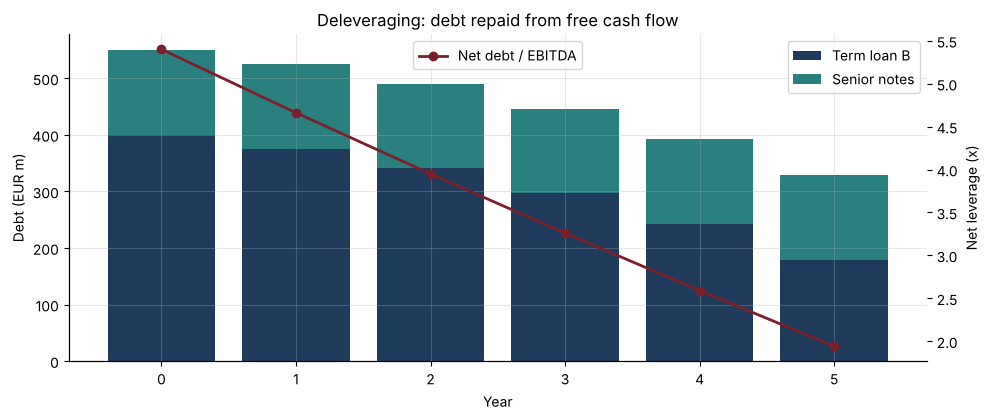

In [3]:
fig, ax1 = plt.subplots(figsize=(10, 4.3))
yrs = np.arange(0, a.years + 1)
tlb = np.concatenate([[a.tlb_multiple * a.entry_ebitda], p["Term loan B"]])
notes = np.concatenate([[a.notes_multiple * a.entry_ebitda], p["Senior notes"]])
ax1.bar(yrs, tlb, color=NAVY, label="Term loan B")
ax1.bar(yrs, notes, bottom=tlb, color=TEAL, label="Senior notes")
ax1.set(xlabel="Year", ylabel="Debt (EUR m)", title="Deleveraging: debt repaid from free cash flow")
ax2 = ax1.twinx()
lev = np.concatenate([[(a.tlb_multiple + a.notes_multiple) - a.min_cash / a.entry_ebitda], p["Net debt / EBITDA"]])
ax2.plot(yrs, lev, color=BORDEAUX, marker="o", lw=2, label="Net debt / EBITDA")
ax2.set_ylabel("Net leverage (x)"); ax2.grid(False)
ax1.legend(loc="upper right"); ax2.legend(loc="upper center")
plt.tight_layout(); plt.savefig("images/deleveraging.png", dpi=150); plt.show()

## 2. Returns and where they come from

Exit at 10x year-5 EBITDA. The **value-creation bridge** splits the equity gain into
EBITDA growth (valued at the entry multiple), multiple expansion, debt paydown and fees.
The parts add up exactly to the gain, which the tests check.

Equity in 480m -> equity out 1,240m :  MoIC 2.58x,  IRR 20.9%


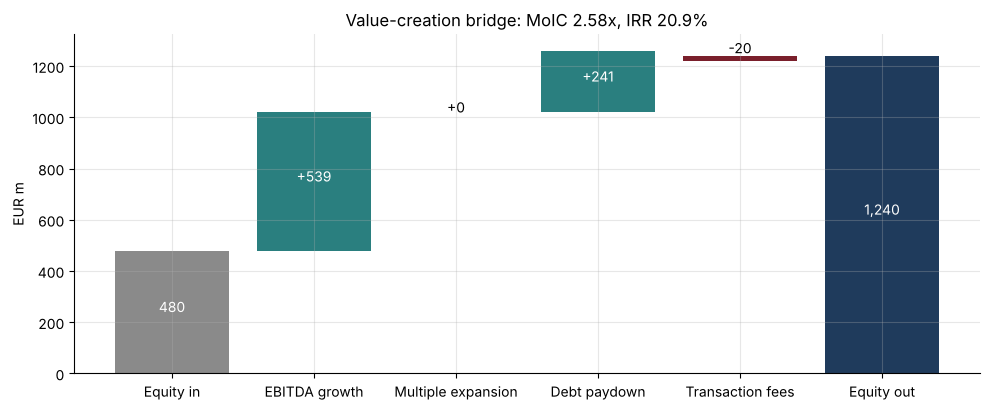

,Share of the gain
EBITDA growth,71%
Multiple expansion,0%
Debt paydown,32%
Transaction fees,-3%


In [4]:
bridge = value_bridge(a, m)
print(f"Equity in {m['entry_equity']:,.0f}m -> equity out {m['exit_equity']:,.0f}m :  MoIC {m['moic']:.2f}x,  IRR {m['irr']:.1%}")
parts = bridge.drop("Total equity gain")
fig, ax = plt.subplots(figsize=(10, 4.2))
running = m["entry_equity"]
ax.bar(0, running, color=GREY); ax.text(0, running / 2, f"{running:,.0f}", ha="center", color="white")
for i, (name, v) in enumerate(parts.items(), start=1):
    ax.bar(i, v, bottom=running if v >= 0 else running + v, color=TEAL if v >= 0 else BORDEAUX)
    ax.text(i, running + v / 2, f"{v:+,.0f}", ha="center", color="white" if abs(v) > 60 else "black")
    running += v
ax.bar(len(parts) + 1, running, color=NAVY); ax.text(len(parts) + 1, running / 2, f"{running:,.0f}", ha="center", color="white")
ax.set_xticks(range(len(parts) + 2), ["Equity in", *parts.index, "Equity out"])
ax.set_ylabel("EUR m"); ax.set_title(f"Value-creation bridge: MoIC {m['moic']:.2f}x, IRR {m['irr']:.1%}")
plt.tight_layout(); plt.savefig("images/value_bridge.png", dpi=150); plt.show()
(bridge / bridge["Total equity gain"]).drop("Total equity gain").to_frame("Share of the gain").style.format("{:.0%}")

Even with no multiple expansion, the deal returns about 21% a year: roughly 70% of the gain
comes from EBITDA growth (sales growth plus margin improvement) and 30% from paying down
debt. A deal that only works if the exit multiple rises is a bet on the market, not on the company.

## 3. Sensitivity tables

The two tables every investment committee asks for.

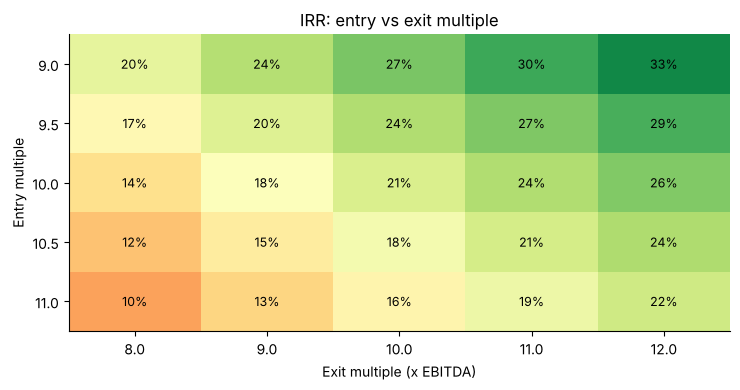

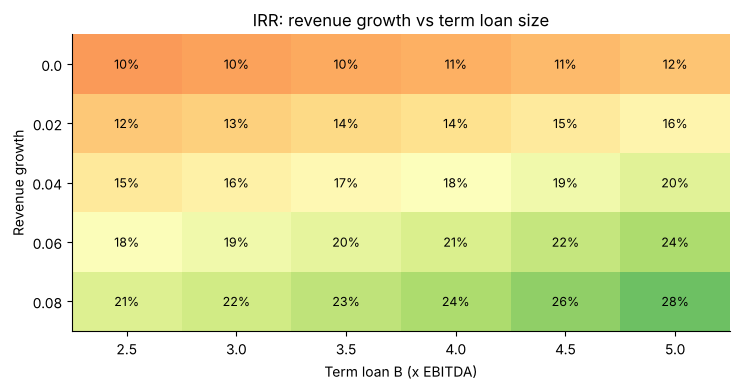

In [5]:
def heat(df, title, fmt="{:.0%}", path=None, xlab="", ylab=""):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    im = ax.imshow(df.values, cmap="RdYlGn", aspect="auto", vmin=0.0, vmax=0.35)
    ax.set_xticks(range(df.shape[1]), [str(c) for c in df.columns]); ax.set_yticks(range(df.shape[0]), [str(r) for r in df.index])
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            ax.text(j, i, fmt.format(df.values[i, j]), ha="center", va="center", fontsize=9)
    ax.set(title=title, xlabel=xlab, ylabel=ylab); ax.grid(False)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

multiples = [8.0, 9.0, 10.0, 11.0, 12.0]
heat(sensitivity(a, "entry_multiple", [9.0, 9.5, 10.0, 10.5, 11.0], "exit_multiple", multiples), "IRR: entry vs exit multiple",
     path="images/irr_multiples.png", xlab="Exit multiple (x EBITDA)", ylab="Entry multiple")
heat(sensitivity(a, "revenue_growth", [0.0, 0.02, 0.04, 0.06, 0.08], "tlb_multiple", [2.5, 3.0, 3.5, 4.0, 4.5, 5.0]),
     "IRR: revenue growth vs term loan size", xlab="Term loan B (x EBITDA)", ylab="Revenue growth")

**Reading the tables.** One turn of exit multiple moves the IRR by about 3 points, as much
as two points of annual sales growth. Each extra turn of term loan adds 2 to 3 points of IRR
in the base case, but the same leverage deepens the losses when things go wrong (next section).

## 4. Downside case

Flat sales, margins slipping to 18%, and an exit at 8x.

In [6]:
down = replace(a, revenue_growth=0.0, margin_target=0.18, exit_multiple=8.0)
md = build_model(down)
print(f"Downside: MoIC {md['moic']:.2f}x, IRR {md['irr']:.1%}; peak leverage {md['projection']['Net debt / EBITDA'].max():.2f}x, "
      f"minimum interest cover {md['projection']['EBITDA / interest'].min():.2f}x")
pd.DataFrame({"Base": [m["irr"], m["moic"], p["Net debt / EBITDA"].iloc[-1]],
              "Downside": [md["irr"], md["moic"], md["projection"]["Net debt / EBITDA"].iloc[-1]]},
             index=["IRR", "MoIC", "Exit leverage"]).round(3)

Downside: MoIC 0.65x, IRR -8.3%; peak leverage 5.24x, minimum interest cover 2.40x


,Base,Downside
IRR,0.209,-0.083
MoIC,2.584,0.648
Exit leverage,1.941,4.546


## 5. Excel output

Investment committees read Excel. The model exports a formatted workbook
(`lbo_model.xlsx`, in this folder) with assumptions, sources and uses, projections and returns.

In [7]:
export_excel(a, m, "lbo_model.xlsx")
print("Sheets:", list(pd.read_excel("lbo_model.xlsx", sheet_name=None)))

Sheets: ['Assumptions', 'Sources & uses', 'Projections', 'Returns']


## Conclusions
- The model balances (sources = uses), never lets debt go negative or cash below its floor,
  and its value bridge adds up exactly (`test_lbo.py`).
- Base case: 2.6x and 21% IRR with no multiple expansion, driven by operations and deleveraging.
- In the downside case the sponsor loses about a third of its equity (0.65x) and still carries
  4.5x leverage at exit, which would make a refinancing or a sale very hard.
- **Next steps:** management equity and ratchets, dividend recapitalisation, PIK notes,
  quarterly covenants, and an add-on acquisition.